![Banner](../images/09_05_banner_rs_hyperspect.png)


# Thematic Applications Across Tanager Scenes

The previous notebooks built a toolbox; this one applies it to four landscapes from the Tanager
sample collection, each with its own spectral question. A burn scar on the Malibu coast is mapped and
measured with burn indices and char spectra; snow, sea ice and open water on Baffin Island are
separated and the 1030 nm ice absorption is tested as a grain size proxy; turbid coastal
water off Venezuela is corrected for sun glint and mapped for sediment and chlorophyll; and iron
oxide rich ground in Bosnia and Herzegovina is found with an index and checked with its spectrum.


## Overview

### Fire and burn severity

Fire removes green leaves (NIR falls), exposes ash, char and soil and dries what remains (SWIR
rises). The **normalised burn ratio**, `NBR = (R860 − R2200) / (R860 + R2200)`, falls from about 0.4
to 0.7 over healthy vegetation to near zero or below over severe burns. With images before and
after a fire the difference (dNBR) measures severity; with one post fire image the NBR and the
spectra of char and ash still outline the burn. Hyperspectral sensors also see **active fires**
through thermal emission in the SWIR and the potassium emission lines at 766 and 770 nm.

### Snow and ice

Snow is the brightest natural surface in the visible and one of the darkest in the SWIR, because ice
absorbs strongly beyond about 1400 nm. The **normalised difference snow index**,
`NDSI = (R560 − R1650) / (R560 + R1650)`, separates snow from clouds and other surfaces. Weaker ice
absorptions at 1030 and 1260 nm deepen as **grain size** grows, because light travels farther through
ice in larger grains; the depth or area of the 1030 nm feature is a classic grain size proxy (Nolin
and Dozier 2000). Impurities (dust, soot, algae) lower the visible reflectance.

### Coastal and inland water

Water leaving radiance is a few percent of the total signal, so atmospheric and **sun glint**
correction matter. A common glint correction subtracts the NIR or SWIR reflectance, where water
leaving signal is negligible, from every band. **Suspended sediment** raises red and NIR reflectance
(roughly linearly up to tens of g m⁻³); **chlorophyll a** creates a dip near 670 nm and a peak near
700 nm, which the normalised difference chlorophyll index, `NDCI = (R708 − R665) / (R708 + R665)`,
exploits in turbid water (Mishra and Mishra 2012); cyanobacteria add a phycocyanin dip near 620 nm.

### Iron oxides and soils

Ferric iron (hematite, goethite) absorbs strongly in the blue and green and weakly near 900 nm,
which makes iron rich soils and rocks red or orange. A red to green ratio, or the depth of the 900 nm
feature, maps them; ferrous iron (in many silicates) absorbs near 1000 nm.


## Thematic Mapping with GeoLattice

Everything here uses functions from earlier notebooks: `hs.read_tanager` (with `bands=` to read only
what each step needs), `hs.index` (NBR_hs, NDCI, FerricIron), `hs.band_depth`, `hs.quality_mask`,
`hs.classify_spectral` and `hs.spectra_at` style pixel picks.

### Learning objectives

1. Map a burn scar and compare the spectra of burned and unburned land.
2. Separate snow, sea ice and open water and test the 1030 nm ice feature as a grain size proxy.
3. Correct water reflectance for sun glint and map turbidity and chlorophyll.
4. Find iron oxide rich surfaces with an index and confirm them by their spectra.

### Data

| Scene | Date | Place |
|---|---|---|
| Tanager fire | 15 December 2024 | Malibu coast, California, after the December 2024 Franklin Fire |
| Tanager snow and ice | 11 April 2025 | Baffin Island, Nunavut, Canada |
| Tanager coastal and water bodies | 25 February 2025 | Paraguaná Peninsula, Venezuela |
| Tanager natural lands | 21 February 2025 | Bosnia and Herzegovina |

### Contents

- Setup
- A burn scar on the Malibu coast
- Snow, sea ice and grain size on Baffin Island
- Turbid water off the Paraguaná Peninsula
- Iron oxides in Bosnia and Herzegovina
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

from matplotlib.colors import ListedColormap  # class colours
from matplotlib.patches import Patch  # legend entries


def bands_near(path, wavelengths_nm):
    """Indices of the Tanager bands nearest to the given wavelengths."""
    probe = hs.read_tanager(path, window=(slice(0, 1), slice(0, 1)))
    return sorted({hs.band_index(probe, w) for w in wavelengths_nm})


def pick(score, mask, q):
    """(row, col) of the pixel in mask whose score is nearest its q-th quantile."""
    s = np.where(mask, score, np.nan)
    return np.unravel_index(np.nanargmin(np.abs(s - np.nanquantile(s, q))), s.shape)


def mean3(cube, rc):
    """Mean 3 x 3 spectrum around (row, col)."""
    r, c = rc
    return cube.values[:, max(r - 1, 0):r + 2, max(c - 1, 0):c + 2].reshape(cube.sizes["band"], -1).mean(1)

GeoLattice 0.3.49


## A burn scar on the Malibu coast

The Franklin Fire started on 9 December 2024 in the Santa Monica Mountains above Malibu. Six days
later Tanager imaged the area. Burned land is found with NBR over the land part of the scene.


land 146 km2 | NBR < 0.05: 23.4 km2 | NBR on land: median 0.29


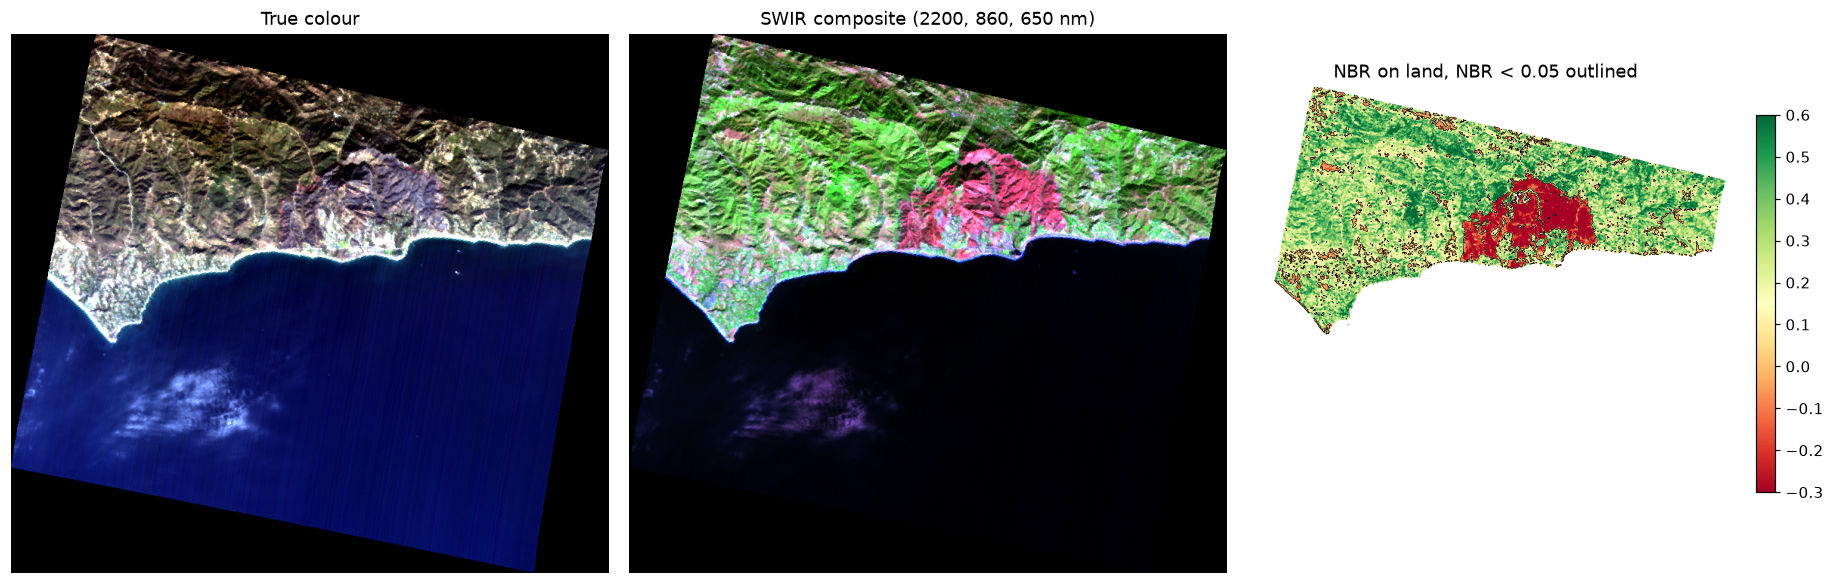

In [2]:
fire_f = tanager_file("fire")
fire = hs.read_tanager(fire_f, bands=bands_near(fire_f, [461, 561, 651, 766, 770, 861, 1650, 2200]))  # 8 bands, whole scene
nbr = hs.index(fire, "NBR_hs")  # (R860 - R2200) / (R860 + R2200)
R, G, N, S2 = (hs.band_at(fire, w).values for w in (651, 561, 861, 2200))
land = ((G - N) / (G + N) < 0) & np.isfinite(N)  # not water
burn = land & (nbr.values < 0.05)  # low NBR on land: burned (or bare) ground
px_area = 30 * 30 / 1e6  # km2 per pixel
print(f"land {land.sum() * px_area:.0f} km2 | NBR < 0.05: {burn.sum() * px_area:.1f} km2 | "
      f"NBR on land: median {np.nanmedian(nbr.values[land]):.2f}")
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
hs.plot_rgb(fire, (651, 561, 461), ax=axes[0], title="True colour")
hs.plot_rgb(fire, (2200, 861, 651), ax=axes[1], title="SWIR composite (2200, 860, 650 nm)")
im = axes[2].imshow(np.where(land, nbr, np.nan), cmap="RdYlGn", vmin=-0.3, vmax=0.6)
axes[2].contour(burn, [0.5], colors="k", linewidths=0.4); axes[2].set_title("NBR on land, NBR < 0.05 outlined"); axes[2].axis("off")
plt.colorbar(im, ax=axes[2], shrink=0.7)
plt.tight_layout()
plt.show()

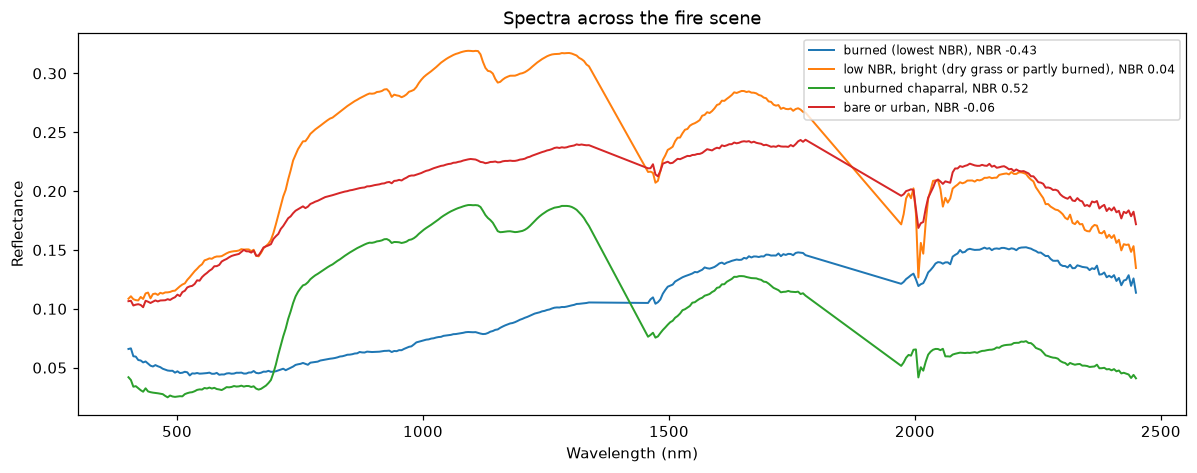

maximum SWIR reflectance on land at 2200 nm: 0.47 (flames would stand far above any surface)


In [3]:
full = hs.read_tanager(fire_f, window=(slice(0, 400), slice(None)))  # all bands, northern (land) part of the scene
full = hs.drop_bad_bands(full)
nb_full = hs.index(full, "NBR_hs").values
lnd = land[:400]
picks = {"burned (lowest NBR)": pick(nb_full, lnd, 0.01), "low NBR, bright (dry grass or partly burned)": pick(nb_full, lnd, 0.15),
         "unburned chaparral": pick(nb_full, lnd, 0.9), "bare or urban": pick(np.where(nb_full < 0.15, hs.band_at(full, 650).values, np.nan), lnd, 0.98)}
wl = hs.wavelengths(full)
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, rc in picks.items():
    s = mean3(full, rc)
    ax.plot(wl, s, lw=1.3, label=f"{name}, NBR {nb_full[rc]:.2f}")
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Spectra across the fire scene"); ax.legend(fontsize=8)
plt.show()
print(f"maximum SWIR reflectance on land at 2200 nm: {np.nanmax(S2[land]):.2f} (flames would stand far above any surface)")

Low NBR outlines a compact burn scar in the mountains, which the SWIR composite shows in magenta
against the green of unburned chaparral. The 23 km² below the threshold include more than the scar:
scattered bare, built up and dry pixels along the coast also fall below 0.05, so the scar itself is
smaller. The spectra explain the index. The burned pixel has lost the red edge and NIR plateau of
vegetation and is dark and nearly flat, rising only slowly into the SWIR (char and ash), while
unburned chaparral keeps a clear red edge. Pixels just below the threshold can still look like dry
vegetation (bright, with a weak red edge), and the "bare or urban" spectrum is twice as bright as
char in the visible: brightness and shape separate them from char, which a single NBR threshold
does not. No pixel on land has SWIR reflectance above about 0.5, so there are no active
flames six days after ignition. With an image from before the fire, dNBR would separate burned land
from naturally bare ground.


## Snow, sea ice and grain size on Baffin Island


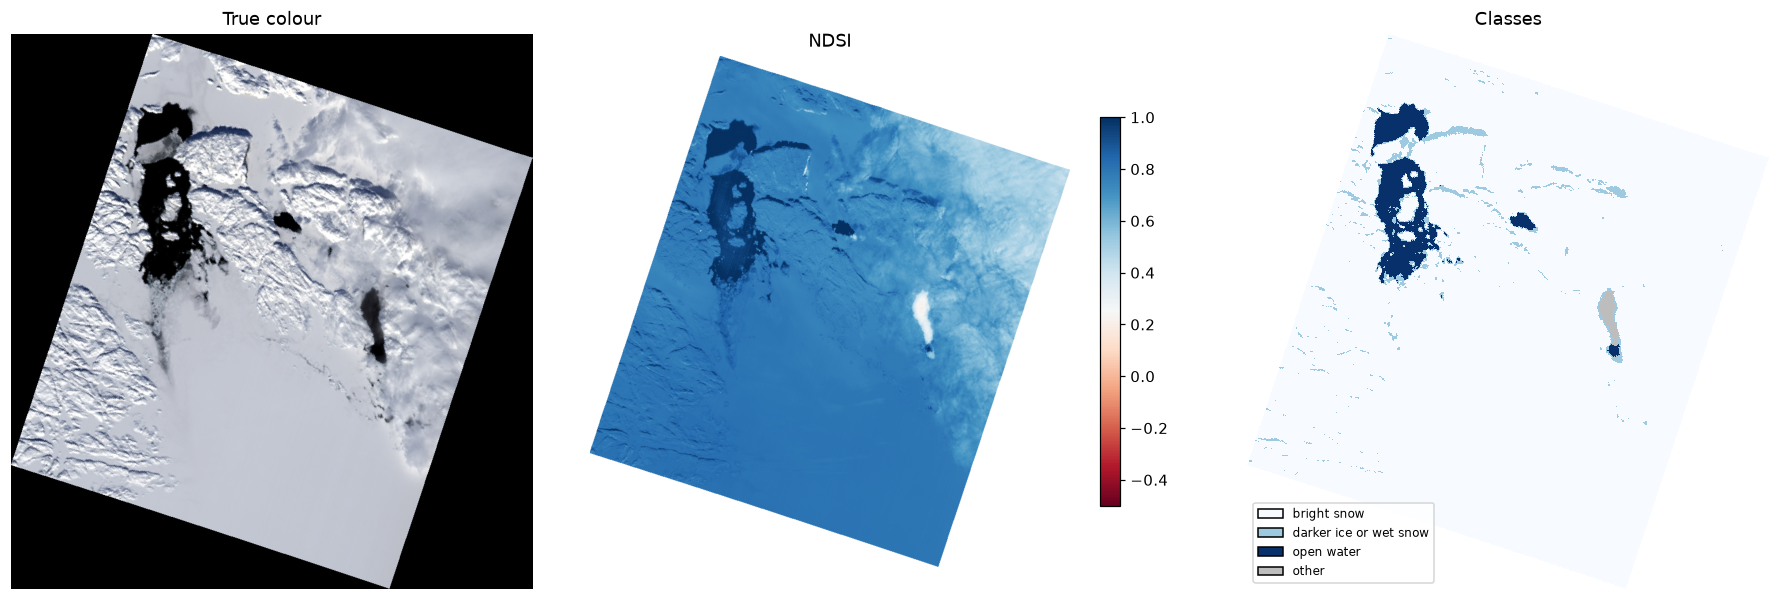

,fraction of the scene
bright snow,0.942
darker ice or wet snow,0.023
open water,0.033
other,0.003


In [4]:
snow_f = tanager_file("snow-ice")
sn = hs.read_tanager(snow_f, wavelength_range=(400, 1700))  # VNIR and the start of the SWIR, whole scene
sn = sn.isel(band=np.flatnonzero(sn["good"].values))
G, N, S1 = (hs.band_at(sn, w).values for w in (560, 860, 1650))
ndsi = (G - S1) / (G + S1)
valid = np.isfinite(G)
cls = np.full(G.shape, np.nan)
cls[valid & (ndsi > 0.4) & (G > 0.5)] = 0  # snow and snow covered ice: bright, high NDSI
cls[valid & (ndsi > 0.4) & (G <= 0.5) & (G > 0.12)] = 1  # darker ice: bare, wet or thin snow
cls[valid & (G <= 0.12) & (N < 0.05)] = 2  # open water: dark, NIR near zero
cls[valid & np.isnan(cls)] = 3  # other: rock, cloud shadow, mixed
names = ["bright snow", "darker ice or wet snow", "open water", "other"]
frac = pd.Series({n: float(np.mean(cls[valid] == i)) for i, n in enumerate(names)})
cmap = ListedColormap(["#f7fbff", "#9ecae1", "#08306b", "#bdbdbd"])
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
hs.plot_rgb(sn, (651, 561, 461), ax=axes[0], title="True colour")
im = axes[1].imshow(ndsi, cmap="RdBu", vmin=-0.5, vmax=1); axes[1].set_title("NDSI"); axes[1].axis("off"); plt.colorbar(im, ax=axes[1], shrink=0.7)
axes[2].imshow(cls, cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="nearest"); axes[2].axis("off"); axes[2].set_title("Classes")
axes[2].legend(handles=[Patch(facecolor=c, edgecolor="k", label=n) for c, n in zip(cmap.colors, names)], fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()
frac.round(3).to_frame("fraction of the scene")

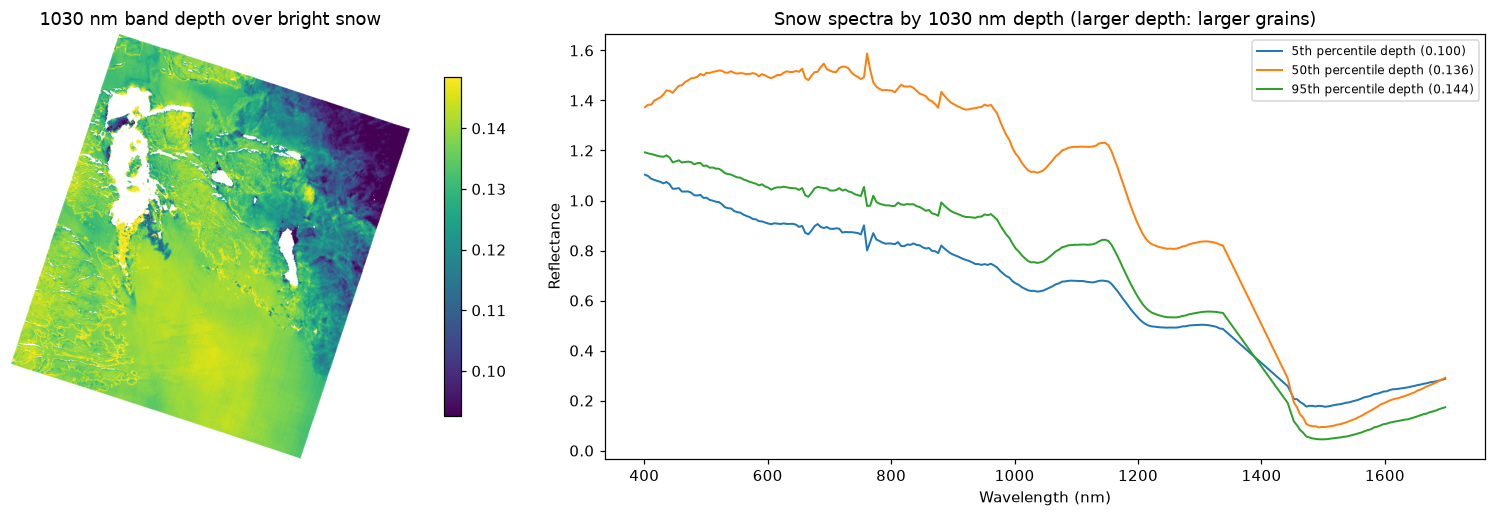

1030 nm depth over bright snow: median 0.136, 5 to 95 percent 0.100 to 0.144


In [5]:
bd = hs.band_depth(hs.smooth(sn, window=5), 1030, 950, 1100)  # ice absorption near 1030 nm
depth = np.where(cls == 0, bd["depth"].values, np.nan)  # bright snow only
qs = {f"{int(q * 100)}th percentile depth": pick(depth, cls == 0, q) for q in (0.05, 0.5, 0.95)}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
im = axes[0].imshow(depth, cmap="viridis", vmin=np.nanpercentile(depth, 2), vmax=np.nanpercentile(depth, 98))
axes[0].set_title("1030 nm band depth over bright snow"); axes[0].axis("off"); plt.colorbar(im, ax=axes[0], shrink=0.8)
w = hs.wavelengths(sn)
for name, rc in qs.items():
    axes[1].plot(w, mean3(sn, rc), lw=1.3, label=f"{name} ({bd['depth'].values[rc]:.3f})")
axes[1].set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Snow spectra by 1030 nm depth (larger depth: larger grains)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"1030 nm depth over bright snow: median {np.nanmedian(depth):.3f}, 5 to 95 percent {np.nanpercentile(depth, 5):.3f} to {np.nanpercentile(depth, 95):.3f}")

The scene is 94 percent bright snow over land and sea ice, with about 3 percent dark open water and
2 percent darker ice. NDSI is high over all snow and ice and low over water. The small bright patch
classed as "other" has low NDSI although it is bright: a cloud, which unlike snow reflects strongly at
1650 nm.

The 1030 nm depth over bright snow varies only between about 0.10 and 0.14, and its map is dominated
by a smooth gradient across the scene and by topographic texture rather than by patches of snow
type. The spectra show why: the median pixel is far brighter than the others (reflectance above 1 on
a sunlit slope), so illumination and slope change the spectra more than grain size does. Band depth,
a ratio to the local continuum, removes much of a brightness change but not the change in path
length and diffuse light with slope and sun angle. Ranking grain size from this map would need a
terrain illumination correction first, and converting depth to micrometres a snow radiative
transfer model.


## Turbid water off the Paraguaná Peninsula

The coastal scene shows clear Caribbean water, a refinery coast and a pale sediment plume. Water is
masked by NDWI, glint is removed by subtracting each pixel's mean reflectance between 1550 and 1650
nm (where water leaving signal is nil), and two water quality proxies are mapped: red reflectance at
650 nm for turbidity and NDCI for chlorophyll.


water: 41% of the scene | SWIR glint over water: median 0.0168, 95th percentile 0.0227


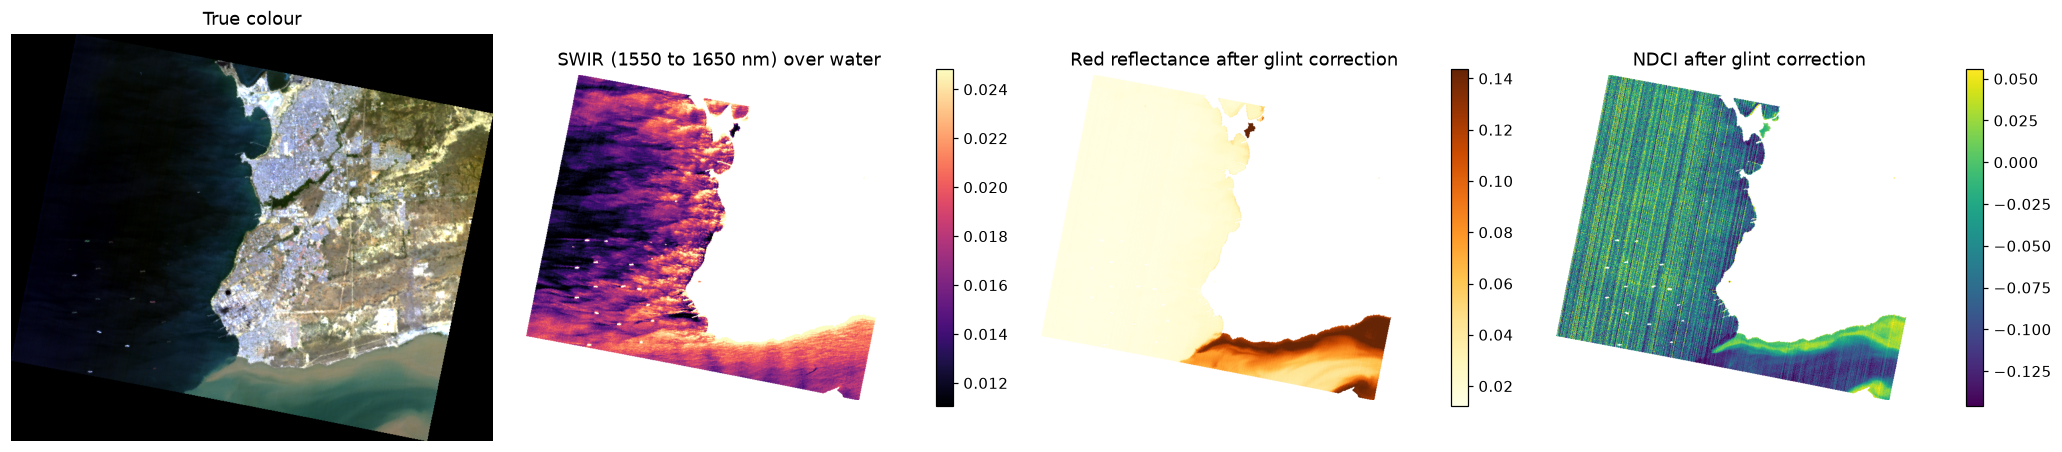

In [6]:
cw_f = tanager_file("coastal-water-bodies")
cw = hs.read_tanager(cw_f, wavelength_range=(400, 1700))
cw = cw.isel(band=np.flatnonzero(cw["good"].values))
G, N = hs.band_at(cw, 560).values, hs.band_at(cw, 860).values
water = ((G - N) / (G + N) > 0.2) & np.isfinite(G)  # water by NDWI
glint = hs.sel_range(cw, 1550, 1650).mean("band").values  # SWIR reflectance (glint, residual offset)
cwc = cw - glint  # glint corrected cube
red = hs.band_at(cwc, 650).values  # turbidity proxy
ndci = hs.index(cwc, "Chl_NDCI").values  # (R708 - R665) / (R708 + R665)
print(f"water: {water.mean():.0%} of the scene | SWIR glint over water: median {np.nanmedian(glint[water]):.4f}, "
      f"95th percentile {np.nanpercentile(glint[water], 95):.4f}")
fig, axes = plt.subplots(1, 4, figsize=(19, 5))
hs.plot_rgb(cw, (651, 561, 461), ax=axes[0], title="True colour")
for ax, (img, t, cmap) in zip(axes[1:], [(glint, "SWIR (1550 to 1650 nm) over water", "magma"),
                                         (red, "Red reflectance after glint correction", "YlOrBr"),
                                         (ndci, "NDCI after glint correction", "viridis")]):
    v = np.where(water, img, np.nan)
    im = ax.imshow(v, cmap=cmap, vmin=np.nanpercentile(v, 2), vmax=np.nanpercentile(v, 98)); ax.set_title(t); ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.65)
plt.tight_layout()
plt.show()

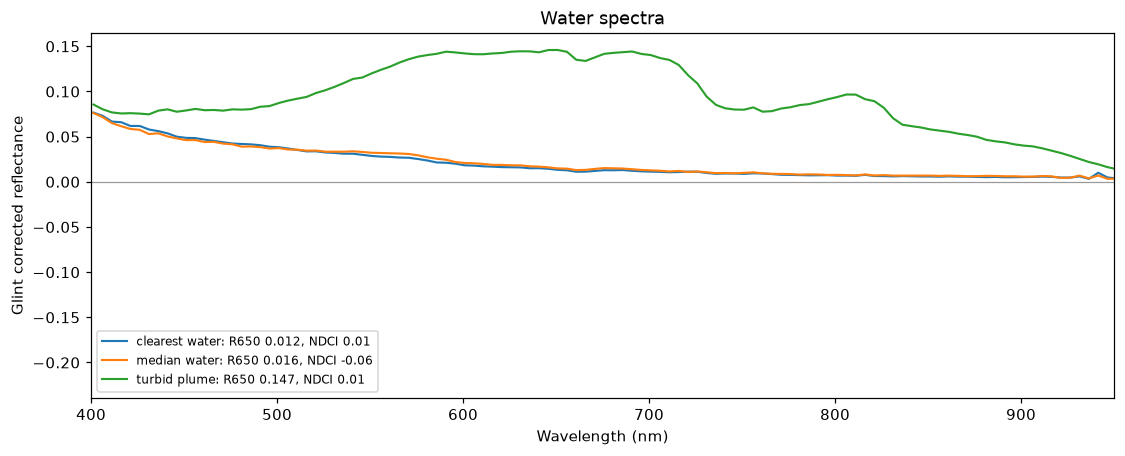

Spearman r between red reflectance and NDCI over water: -0.34


In [7]:
w = hs.wavelengths(cwc)
picks = {"clearest water": pick(red, water, 0.02), "median water": pick(red, water, 0.5),
         "turbid plume": pick(red, water, 0.99)}
fig, ax = plt.subplots(figsize=(12, 4.3))
for name, rc in picks.items():
    ax.plot(w, mean3(cwc, rc), lw=1.4, label=f"{name}: R650 {red[rc]:.3f}, NDCI {ndci[rc]:.2f}")
ax.set(xlim=(400, 950), xlabel="Wavelength (nm)", ylabel="Glint corrected reflectance", title="Water spectra"); ax.legend(fontsize=8)
ax.axhline(0, color="0.6", lw=0.8)
plt.show()
r_ok = water & np.isfinite(red) & np.isfinite(ndci)
print(f"Spearman r between red reflectance and NDCI over water: {pd.Series(red[r_ok]).corr(pd.Series(ndci[r_ok]), method='spearman'):.2f}")

Over water the SWIR reflectance is small but not zero (about 0.017), and its pattern of wind streaks
and wave fields is the sun glint that the correction removes; it is also higher next to the plume and
the coast, where adjacency effects from the bright land and sediment add light. After correction the clearest water is blue with a
reflectance of a few percent at 450 nm and almost nothing beyond 600 nm, typical of oligotrophic
Caribbean water, while the plume raises the green, red and NIR strongly: suspended sediment
scatters light at all wavelengths. The NDCI map is the cautionary
part. In clear water both its bands are close to zero, so the index is dominated by noise and by the
detector stripes; it only becomes meaningful where the water is productive or turbid. Over all water
NDCI and red reflectance are weakly negatively correlated (r about -0.34), and in the plume the 708 nm
reflectance is set by sediment scattering, not by chlorophyll; separating the two requires
bio-optical models or field samples. Red reflectance alone is a robust relative turbidity
map; converting it to g m⁻³ needs a calibration such as Nechad et al. (2010).


## Iron oxides in Bosnia and Herzegovina

The winter scene of the natural lands collection shows dormant forest and fields and a conspicuous
red brown patch. The ferric iron index (R750 / R560) finds such surfaces; the spectra confirm what
they are.


iron oxide candidates: 2,391 pixels (2.15 km2)


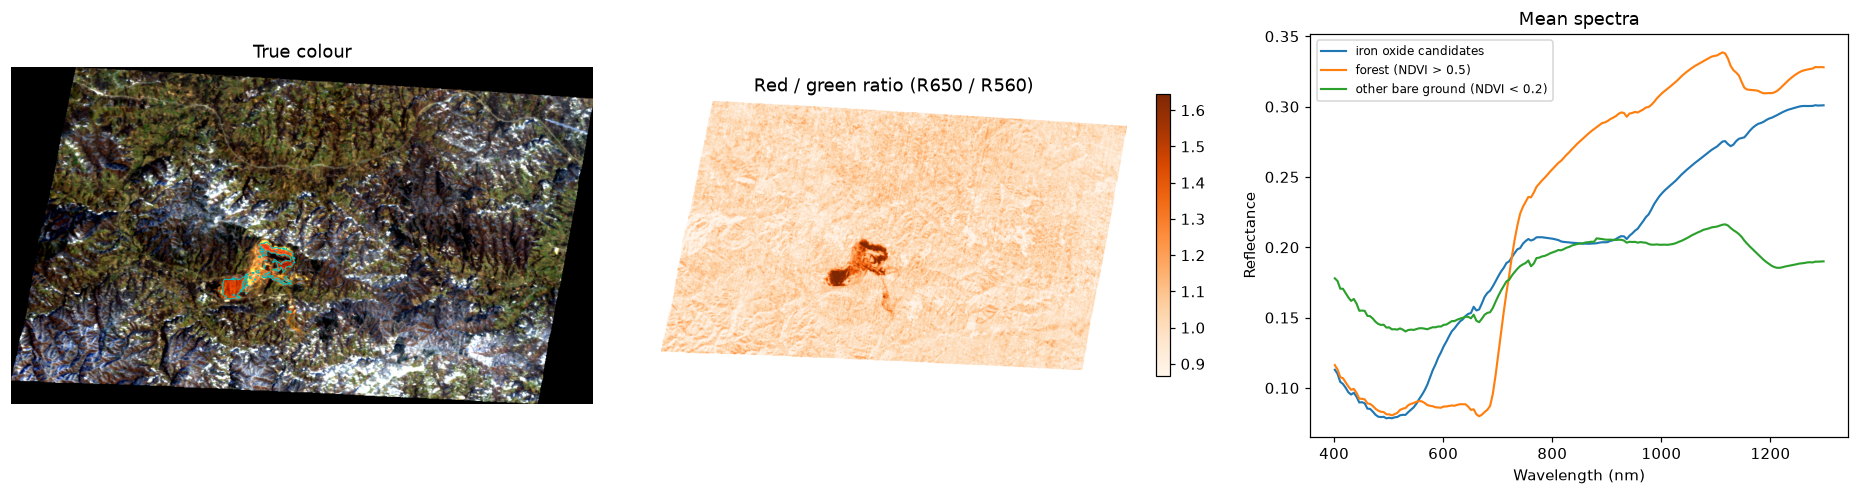

depth of the ~900 nm ferric iron feature (continuum removed, 750 to 1250 nm): {'iron oxide candidates': 0.146, 'forest (NDVI > 0.5)': 0.064, 'other bare ground (NDVI < 0.2)': 0.055}


In [8]:
nl_f = tanager_file("natural-lands")
nl = hs.read_tanager(nl_f, wavelength_range=(400, 1300))
nl = nl.isel(band=np.flatnonzero(nl["good"].values))
fe = hs.index(nl, "FerricIron").values  # R750 / R560
R, G, B, N = (hs.band_at(nl, w).values for w in (650, 560, 460, 860))
ndvi = (N - R) / (N + R)
red_ratio = R / G  # red to green ratio: iron oxides are red
valid = np.isfinite(fe)
iron = valid & (red_ratio > np.nanpercentile(red_ratio[valid], 99.5)) & (ndvi < 0.3)  # reddest, non vegetated pixels
print(f"iron oxide candidates: {iron.sum():,} pixels ({iron.sum() * 900 / 1e6:.2f} km2)")
rows_, cols_ = np.nonzero(iron)
r0, c0 = int(np.median(rows_)), int(np.median(cols_))  # centre of the candidates
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.3, 1.3, 1.2]})
hs.plot_rgb(nl, (651, 561, 461), ax=axes[0], title="True colour"); axes[0].contour(iron, [0.5], colors="c", linewidths=0.6)
im = axes[1].imshow(red_ratio, cmap="Oranges", vmin=np.nanpercentile(red_ratio, 2), vmax=np.nanpercentile(red_ratio, 99.8))
axes[1].set_title("Red / green ratio (R650 / R560)"); axes[1].axis("off"); plt.colorbar(im, ax=axes[1], shrink=0.7)
w = hs.wavelengths(nl)
spec = {"iron oxide candidates": nl.values[:, iron].mean(1),
        "forest (NDVI > 0.5)": np.nanmean(nl.values[:, ndvi > 0.5], 1),
        "other bare ground (NDVI < 0.2)": np.nanmean(nl.values[:, (ndvi < 0.2) & ~iron & valid], 1)}
for n, s in spec.items():
    axes[2].plot(w, s, lw=1.4, label=n)
axes[2].set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Mean spectra"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
cr = hs.continuum_removal(hs.as_cube(np.array(list(spec.values())).T[:, None, :], w), start=750, stop=1250)
print("depth of the ~900 nm ferric iron feature (continuum removed, 750 to 1250 nm):",
      {n: round(float(1 - cr.values[:, 0, i].min()), 3) for i, n in enumerate(spec)})

The reddest non vegetated pixels form the compact patch seen in the true colour image, and their mean
spectrum has what iron oxides predict: low reflectance in the blue and green, a steep rise into the
red, and a broad absorption between about 850 and 950 nm whose depth after continuum removal is
larger than for other bare ground or forest. Without field knowledge the material can be called
iron oxide rich (exposed red soil, weathered rock, tailings or similar), not identified more exactly;
matching against laboratory spectra of hematite and goethite would be the next step (notebook
09_05_06).


## Summary and exercises

**Key points**

- Burn scars show low NBR and dark, flat char spectra; brightness and shape separate them from bare
  ground and dry vegetation, and a pre fire image would give burn severity.
- NDSI separates snow and ice from water, rock and cloud; the 1030 nm ice absorption is a grain size
  proxy, but on rugged terrain illumination must be corrected first.
- Coastal water needs glint correction; red reflectance maps turbidity, while NDCI is noise in clear
  water and confounded by sediment in turbid water.
- Iron oxide rich surfaces are found with a red to green ratio and confirmed by their 900 nm feature.

**`geolattice.rsense.hyperspectral` functions used:** `read_tanager`, `drop_bad_bands`, `index`,
`band_at`, `band_depth`, `sel_range`, `smooth`, `continuum_removal`, `as_cube`, `plot_rgb`.

**Exercises**

1. Map the burn scar with the 2200 nm and 1650 nm bands separately (two versions of NBR). Which shows
   the scar more clearly?
2. Use the 1260 nm ice absorption instead of 1030 nm on Baffin Island. Do the two depth maps agree?
3. Correct the coastal water with the 860 nm band instead of the SWIR mean. What happens in the plume?
4. Repeat the iron oxide search in the Permian Basin scene and compare the spectra with the Bosnian
   patch.
